# CS03 - Undervoltage at a remote industrial zone (5-bus, Niamey context)

**Problem type:** voltage drop / undervoltage, and how to fix it.
**Source:** Travaux pratiques, case 2. Fictitious, educational grid; real solar profile.

## 1. Context
| Bus | Equipment | Design value |
|---|---|---|
| 1 | Thermal power station | slack, 1.02 p.u. |
| 2 | Substation | 25 MW + 8 MVAr |
| 3 | Solar PV plant | 40 MW |
| 4 | Urban area | 45 MW + 15 MVAr |
| 5 | Remote industrial zone | 35 MW + 18 MVAr, at the end of an **85 km** 132 kV line |

The exercise statement *assumed* $V_5 = 0.92$ p.u. Here we **compute** it.

## 2. Exercise
1. Compute the voltage profile. Which bus violates the 0.95 p.u. limit, and why?
2. Is the worst case at midday (PV at 40 MW) or at the evening peak (no PV)?
3. Compare five remedies: capacitor bank, higher set point at the plant, second circuit,
   reactive support from the PV inverters, SVC/STATCOM. Which one would you recommend?
4. Size the capacitor bank. Check the whole day with the real profile.

## 3. Theory: why the voltage drops
For a line with impedance $R + jX$ carrying $P + jQ$ towards the receiving end,
$$\Delta V \approx \frac{R\,P + X\,Q}{V}.$$
On this 85 km line $X = 33$ ohm and $R = 10$ ohm: every MVAr transported costs three times
more voltage than every MW. The industrial load is **reactive** (power factor 0.89), so the
cheapest remedy is to produce reactive power **locally**, at bus 5.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.kpi import run_pf, kpis, one_snapshot, branch_table
from pscs.plotting import SERIES, CRITICAL, GOOD, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()
n = pypsa.Network(DATA / "networks" / "niamey_5bus")
n.lines[["bus0", "bus1", "length", "r", "x", "s_nom"]]

,bus0,bus1,length,r,x,s_nom
name,,,,,,
L1-2,1,2,30.0,3.6,11.70,100.0
L1-3,1,3,25.0,3.0,9.75,100.0
L2-4,2,4,35.0,4.2,13.65,100.0
L3-4,3,4,30.0,3.6,11.70,100.0
L4-5,4,5,85.0,10.2,33.15,100.0


## 4. Two design points
* **A - exercise statement:** all loads at their peak and the PV plant at 40 MW.
* **B - realistic evening peak (19:00):** loads at their peak, **no sun**. This is the
  true worst case in the Sahel, where the peak is driven by lighting and cooling after
  sunset.

In [2]:
PEAK = {"substation": (25, 8), "urban": (45, 15), "industry": (35, 18)}


def design_point(pv_mw=40.0, modify=None):
    m = one_snapshot(n, n.snapshots[19])
    for ld, (p, q) in PEAK.items():
        m.loads_t.p_set.loc[:, ld], m.loads_t.q_set.loc[:, ld] = p, q
    m.generators_t.p_set.loc[:, "pv"] = pv_mw
    if modify:
        modify(m)
    run_pf(m)
    return m

A_ = design_point(40.0)
B_ = design_point(0.0)
profile = pd.DataFrame({"A: PV 40 MW (statement)": A_.buses_t.v_mag_pu.iloc[0],
                        "B: evening peak, no PV": B_.buses_t.v_mag_pu.iloc[0]})
profile.to_csv(TAB / "cs03_voltage_profile.csv")
print("losses A: %.2f MW, B: %.2f MW" % (kpis(A_)["losses (MW)"], kpis(B_)["losses (MW)"]))
profile.round(4)

losses A: 2.68 MW, B: 3.18 MW


,A: PV 40 MW (statement),"B: evening peak, no PV"
name,,
1,1.0200,1.0200
2,0.9965,0.9944
3,1.0060,1.0003
4,0.9806,0.9765
5,0.9231,0.9187


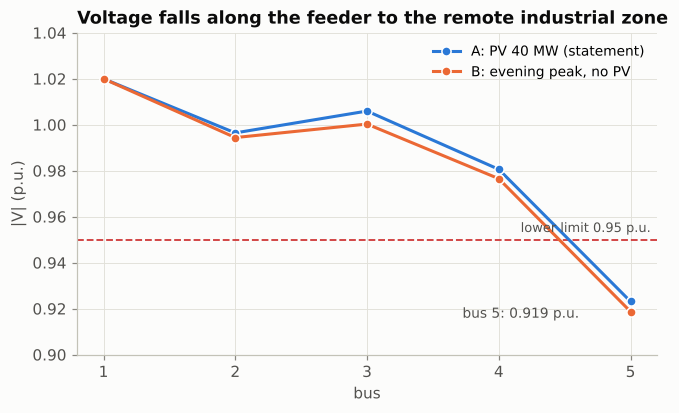

In [3]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
for (lab, s), c in zip(profile.items(), SERIES):
    ax.plot(s.index, s.values, "o-", color=c, label=lab, markeredgecolor="white")
limit_line(ax, 0.95, "lower limit 0.95 p.u.", color=CRITICAL)
ax.annotate(f"bus 5: {profile.iloc[4, 1]:.3f} p.u.", (4, profile.iloc[4, 1]), xytext=(-110, -4),
            textcoords="offset points", fontsize=9, color=INK2)
ax.set_ylim(0.90, 1.04)
ax.set_xlabel("bus"); ax.set_ylabel("|V| (p.u.)")
ax.set_title("Voltage falls along the feeder to the remote industrial zone")
ax.legend(loc="upper right")
save(fig, FIG / "cs03_voltage_profile.png")
fig

**Reading:** only bus 5 is out of limits. The drop from bus 4 to bus 5 (about 6 %) is much
larger than anywhere else: it is caused by the length of line 4-5 and by the 18 MVAr of the
industrial load. The PV plant at bus 3 hardly helps bus 5 (A and B differ by less than
0.01 p.u.): **the worst case is the evening peak (B)**, and remedies must be sized for it.

## 5. Five remedies, compared at the worst case (B)

In [4]:
def cap(q_mvar):
    def f(m):
        m.add("ShuntImpedance", "cap5", bus="5", b=q_mvar / 132**2)
    return f


def setpoint(m):
    m.buses.loc["1", "v_mag_pu_set"] = 1.05


def second_circuit(m):
    m.lines.loc["L4-5", ["r", "x"]] /= 2
    m.lines.loc["L4-5", "b"] *= 2


def pv_q_at_night(m):          # inverters operate as a STATCOM (P = 0) holding 1.03 p.u.
    m.generators.loc["pv", "control"] = "PV"
    m.buses.loc["3", "v_mag_pu_set"] = 1.03


def svc5(m):                   # SVC/STATCOM at bus 5 holding 0.97 p.u.
    m.add("Generator", "svc5", bus="5", control="PV", p_set=0.0, p_nom=1)
    m.buses.loc["5", "v_mag_pu_set"] = 0.97

# minimum capacitor that restores 0.95 p.u. (bisection on the AC load flow)
lo, hi = 0.0, 30.0
for _ in range(30):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if design_point(0, cap(mid)).buses_t.v_mag_pu.iloc[0]["5"] < 0.95 else (lo, mid)
q_min_cap = hi
print(f"Smallest capacitor bank giving V5 >= 0.95 p.u.: {q_min_cap:.1f} MVAr at 1 p.u.")

remedies = {
    "none": None,
    "capacitor 15 MVAr at bus 5": cap(15.0),
    "plant set point 1.05 p.u.": setpoint,
    "second circuit on line 4-5": second_circuit,
    "PV inverters Q-at-night, 1.03 p.u.": pv_q_at_night,
    "SVC/STATCOM at bus 5 (0.97 p.u.)": svc5,
}
rows = {}
for name, fn in remedies.items():
    m = design_point(0.0, fn)
    v = m.buses_t.v_mag_pu.iloc[0]
    q = m.generators_t.q.iloc[0]
    rows[name] = {"V5 (p.u.)": v["5"], "V4 (p.u.)": v["4"], "V1 (p.u.)": v["1"],
                  "losses (MW)": kpis(m)["losses (MW)"],
                  "Q from device (MVAr)": (q.get("svc5", np.nan) if "SVC" in name else
                                           q["pv"] if "PV inv" in name else
                                           15 * v["5"] ** 2 if "capacitor" in name else np.nan)}
rem = pd.DataFrame(rows).T
rem["meets 0.95"] = rem["V5 (p.u.)"] >= 0.95
rem.to_csv(TAB / "cs03_remedies.csv")
rem.round(4)

Smallest capacitor bank giving V5 >= 0.95 p.u.: 11.8 MVAr at 1 p.u.


,V5 (p.u.),V4 (p.u.),V1 (p.u.),losses (MW),Q from device (MVAr),meets 0.95
none,0.9187,0.9765,1.02,3.1771,NaN,False
capacitor 15 MVAr at bus 5,0.9588,0.9869,1.02,2.7184,13.7881,True
plant set point 1.05 p.u.,0.9532,1.0085,1.05,2.9559,NaN,True
second circuit on line 4-5,0.9557,0.9809,1.02,2.4839,NaN,True
"PV inverters Q-at-night, 1.03 p.u.",0.9415,0.9977,1.02,3.2169,68.1189,False
SVC/STATCOM at bus 5 (0.97 p.u.),0.9700,0.9898,1.02,2.6599,17.8977,True


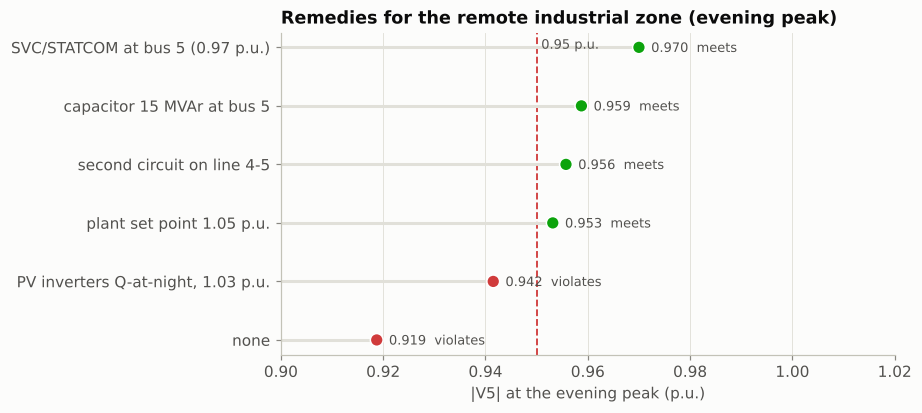

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
order = rem["V5 (p.u.)"].sort_values()
y = np.arange(len(order))
ax.hlines(y, 0.90, order.values, color="#e1e0d9", lw=2)
ax.scatter(order.values, y, s=70, zorder=3, edgecolor="white",
           color=[GOOD if v >= 0.95 else CRITICAL for v in order.values])
for yi, v in zip(y, order.values):
    ax.annotate(f"{v:.3f}  {'meets' if v >= 0.95 else 'violates'}", (v, yi), xytext=(8, -3),
                textcoords="offset points", fontsize=8.5, color=INK2)
limit_line(ax, 0.95, "0.95 p.u.", color=CRITICAL, axis="x")
ax.set_yticks(y); ax.set_yticklabels(order.index)
ax.set_xlim(0.90, 1.02); ax.set_xlabel("|V5| at the evening peak (p.u.)")
ax.set_title("Remedies for the remote industrial zone (evening peak)")
ax.grid(axis="y", visible=False)
save(fig, FIG / "cs03_remedies.png")
fig

**Reading the comparison**
* **Capacitor bank at bus 5** - the classic answer: reactive power produced where it is
  consumed. 15 MVAr (three steps of 5 MVAr) restores the voltage with margin and also
  **reduces the losses** (less reactive current in the long line). Cheapest option.
* **Higher set point at the plant (1.05 p.u.)** - raises the whole profile and fixes bus 5,
  but it uses up the upper margin at bus 1 and does not remove the cause.
* **Second circuit** - halves the line impedance: good voltage and the lowest losses, but by
  far the most expensive and slowest option (new line, rights of way).
* **PV inverters at night** - bus 3 is electrically far from bus 5, so the inverters must
  inject about 68 MVAr, more than a 44 MVA inverter can deliver, and bus 5 still stays
  below 0.95 p.u. Useful as a complement, not as the solution.
* **SVC/STATCOM at bus 5** - precise, continuous control and fast response; more expensive
  than a capacitor bank. The right choice if the industrial load is very variable
  (arc furnaces, large motors starting).

**Recommendation:** a 15 MVAr switched capacitor bank at bus 5 (three steps of 5 MVAr),
then re-assess with load growth; keep the second circuit as the long-term option.

## 6. Voltage sensitivity: how many MVAr per percent of voltage?

dV5/dQ = 0.28 % per MVAr  ->  3.6 MVAr per percent of voltage


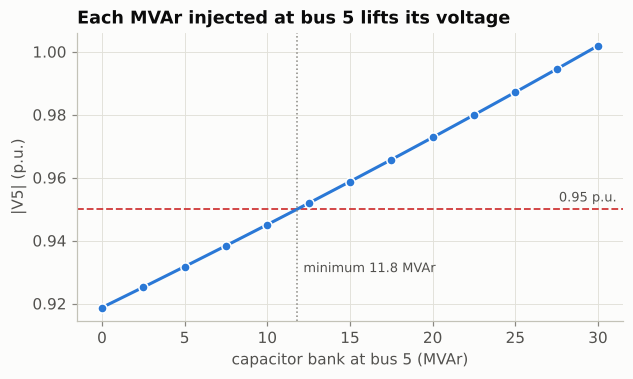

In [6]:
qs = np.arange(0, 31, 2.5)
v5 = [design_point(0, cap(q)).buses_t.v_mag_pu.iloc[0]["5"] for q in qs]
sens = np.polyfit(qs, v5, 1)[0]
print(f"dV5/dQ = {100 * sens:.2f} % per MVAr  ->  {0.01 / sens:.1f} MVAr per percent of voltage")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(qs, v5, "o-", color=SERIES[0], markeredgecolor="white")
limit_line(ax, 0.95, "0.95 p.u.", color=CRITICAL)
ax.axvline(q_min_cap, color=MUTED, ls=":", lw=1)
ax.annotate(f"minimum {q_min_cap:.1f} MVAr", (q_min_cap, 0.93), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("capacitor bank at bus 5 (MVAr)"); ax.set_ylabel("|V5| (p.u.)")
ax.set_title("Each MVAr injected at bus 5 lifts its voltage")
save(fig, FIG / "cs03_q_sensitivity.png")
fig

## 7. The whole day with the real solar profile
We run the 24 AC load flows of 4 May 2023 without and with the 15 MVAr bank.

In [7]:
def day_run(with_cap):
    m = n.copy()
    if with_cap:
        m.add("ShuntImpedance", "cap5", bus="5", b=15 / 132**2)
    run_pf(m)
    return m

d0, d1 = day_run(False), day_run(True)
day = pd.DataFrame({"V5 without bank": d0.buses_t.v_mag_pu["5"],
                    "V5 with 15 MVAr bank": d1.buses_t.v_mag_pu["5"],
                    "losses without (MW)": (d0.lines_t.p0 + d0.lines_t.p1).sum(axis=1),
                    "losses with (MW)": (d1.lines_t.p0 + d1.lines_t.p1).sum(axis=1)})
day.index = day.index.hour
day.to_csv(TAB / "cs03_day.csv")
print("hours below 0.95 p.u.: without bank %d, with bank %d" %
      ((day["V5 without bank"] < 0.95).sum(), (day["V5 with 15 MVAr bank"] < 0.95).sum()))
print("highest V5 with the bank: %.3f p.u. (no overvoltage at night)" % day["V5 with 15 MVAr bank"].max())
print("daily losses: %.1f MWh -> %.1f MWh" % (day["losses without (MW)"].sum(), day["losses with (MW)"].sum()))

hours below 0.95 p.u.: without bank 24, with bank 0
highest V5 with the bank: 0.977 p.u. (no overvoltage at night)
daily losses: 59.7 MWh -> 50.1 MWh


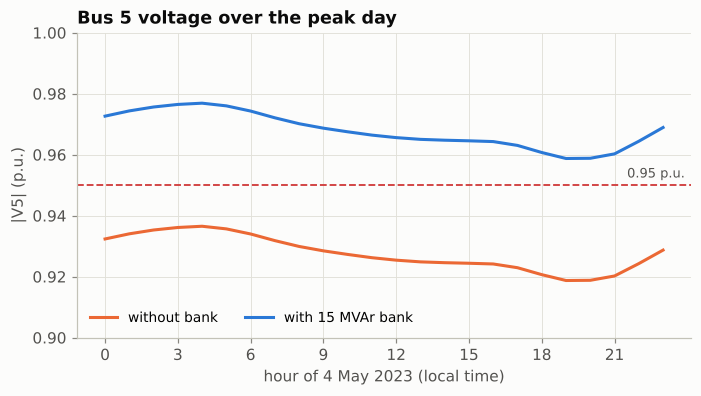

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(day.index, day["V5 without bank"], color=SERIES[1], label="without bank")
ax.plot(day.index, day["V5 with 15 MVAr bank"], color=SERIES[0], label="with 15 MVAr bank")
limit_line(ax, 0.95, "0.95 p.u.", color=CRITICAL)
ax.set_xticks(range(0, 24, 3)); ax.set_ylim(0.90, 1.0)
ax.set_xlabel("hour of 4 May 2023 (local time)"); ax.set_ylabel("|V5| (p.u.)")
ax.set_title("Bus 5 voltage over the peak day")
ax.legend(loc="lower left", ncol=2)
save(fig, FIG / "cs03_day_v5.png")
fig

## 8. Interpretation
* Without action, bus 5 is below 0.95 p.u. **24 hours out of 24**, not only at the peak: the
  industrial load is almost flat. This is a **structural** problem of distance and reactive
  demand, not a peak-hour accident.
* The 15 MVAr bank keeps bus 5 inside the limits all day without creating an overvoltage
  at night, and it cuts the daily losses.

**What to say:** "In the five-bus network the problem is localised: bus 5 drops to about
0.92 p.u. because it is fed through a long line and its load is strongly reactive. The PV
plant does not help, because it is far away and the peak occurs after sunset. A 15 MVAr
capacitor bank at bus 5 restores the voltage all day and reduces the losses; a second
circuit is the long-term solution if demand keeps growing."

In [9]:
pscs.save_summary("cs03", {
    "V5_A": profile.iloc[4, 0], "V5_B": profile.iloc[4, 1],
    "q_min_cap": q_min_cap, "dV_per_MVAr_pct": 100 * sens,
    "remedies": rem["V5 (p.u.)"].to_dict(), "losses": rem["losses (MW)"].to_dict(),
    "q_pv_night": rem.loc["PV inverters Q-at-night, 1.03 p.u.", "Q from device (MVAr)"],
    "q_svc": rem.loc["SVC/STATCOM at bus 5 (0.97 p.u.)", "Q from device (MVAr)"],
    "hours_below_without": int((day["V5 without bank"] < 0.95).sum()),
    "hours_below_with": int((day["V5 with 15 MVAr bank"] < 0.95).sum()),
    "loss_day_without": day["losses without (MW)"].sum(), "loss_day_with": day["losses with (MW)"].sum(),
})